<a href="https://colab.research.google.com/github/camtop007/BDA-400-Assignment-1/blob/main/KamilAdebumola_BDA750_KNN_AIClassifier_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Colab includes scikit-learn, pandas and matplotlib in most runtimes.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
X_array, y_array = make_classification(
    n_samples=450, n_features=6, n_informative=4, n_redundant=0,
    n_classes=3, n_clusters_per_class=1, class_sep=1.25,
    random_state=RANDOM_STATE
)
feature_names = [f"feature_{i+1}" for i in range(X_array.shape[1])]
df = pd.DataFrame(X_array, columns=feature_names)
df['target'] = y_array
print('Shape:', df.shape)
print('Target distribution:')
print(df['target'].value_counts().sort_index())
display(df.head())


Shape: (450, 7)
Target distribution:
target
0    151
1    148
2    151
Name: count, dtype: int64


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,target
0,-1.337618,-2.182784,-1.434451,1.267387,-0.048965,-2.590546,1
1,1.224799,-0.207420,0.407062,1.446761,-0.844279,1.366836,1
2,0.139279,-0.671332,-0.453122,1.532143,-0.588236,-0.026637,2
3,3.090618,-1.702485,-3.461518,-0.764923,-1.003891,0.042483,2
4,0.387992,-1.925081,-2.039547,-1.388093,0.903481,0.461512,0


In [2]:
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
base_model = KNeighborsClassifier(n_neighbors=5, weights='uniform', metric='minkowski', p=2)
base_model.fit(X_train, y_train)
base_predictions = base_model.predict(X_test)
base_accuracy = accuracy_score(y_test, base_predictions)
print(f'Baseline test accuracy: {base_accuracy:.4f}')
print(classification_report(y_test, base_predictions, zero_division=0))


Baseline test accuracy: 0.8667
              precision    recall  f1-score   support

           0       0.78      0.93      0.85        30
           1       0.91      0.70      0.79        30
           2       0.94      0.97      0.95        30

    accuracy                           0.87        90
   macro avg       0.88      0.87      0.86        90
weighted avg       0.88      0.87      0.86        90



In [3]:
pipeline = Pipeline([
    ('scale', 'passthrough'),
    ('knn', KNeighborsClassifier())
])
param_grid = {
    'scale': ['passthrough', StandardScaler()],
    'knn__n_neighbors': [3, 5, 7, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(
    pipeline, param_grid, cv=cv, scoring='accuracy', n_jobs=-1,
    return_train_score=True
)
search.fit(X_train, y_train)
results = pd.DataFrame(search.cv_results_)
columns = ['param_scale','param_knn__n_neighbors','param_knn__weights',
           'param_knn__metric','mean_test_score','std_test_score']
display(results[columns].sort_values('mean_test_score', ascending=False).head(12))
print('Best training CV parameters:', search.best_params_)
print('Best training CV accuracy:', round(search.best_score_, 4))


,param_scale,param_knn__n_neighbors,param_knn__weights,param_knn__metric,mean_test_score,std_test_score
13,StandardScaler(),11,uniform,euclidean,0.825000,0.039869
25,StandardScaler(),7,uniform,manhattan,0.805556,0.050461
21,StandardScaler(),5,uniform,manhattan,0.802778,0.053720
15,StandardScaler(),11,distance,euclidean,0.802778,0.045980
5,StandardScaler(),5,uniform,euclidean,0.800000,0.046976
23,StandardScaler(),5,distance,manhattan,0.794444,0.040635
24,passthrough,7,uniform,manhattan,0.794444,0.032155
27,StandardScaler(),7,distance,manhattan,0.791667,0.045644
20,passthrough,5,uniform,manhattan,0.791667,0.031672
29,StandardScaler(),11,uniform,manhattan,0.786111,0.039869


Best training CV parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 11, 'knn__weights': 'uniform', 'scale': StandardScaler()}
Best training CV accuracy: 0.825


Baseline held-out accuracy: 0.8667
Tuned held-out accuracy:    0.8444
Difference (tuned-base):   -0.0222
Independent check:        0.8444
              precision    recall  f1-score   support

           0       0.78      0.93      0.85        30
           1       0.95      0.63      0.76        30
           2       0.85      0.97      0.91        30

    accuracy                           0.84        90
   macro avg       0.86      0.84      0.84        90
weighted avg       0.86      0.84      0.84        90



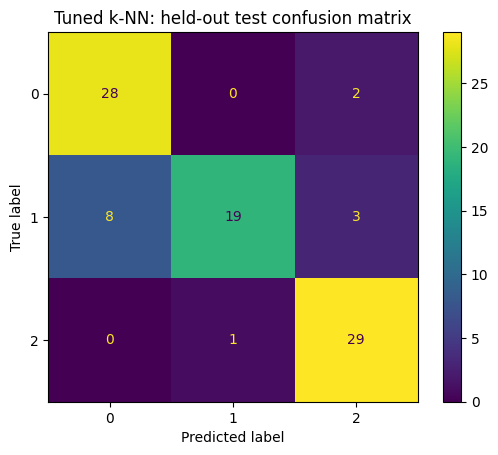

,actual,predicted
0,2,2
1,0,0
2,1,0
3,2,2
4,1,0
5,2,2
6,2,2
7,1,0
8,1,2
9,0,0


In [4]:
tuned_predictions = search.best_estimator_.predict(X_test)
tuned_accuracy = accuracy_score(y_test, tuned_predictions)
manual_accuracy = sum(int(actual == predicted) for actual, predicted in zip(y_test, tuned_predictions)) / len(y_test)
print(f'Baseline held-out accuracy: {base_accuracy:.4f}')
print(f'Tuned held-out accuracy:    {tuned_accuracy:.4f}')
print(f'Difference (tuned-base):   {tuned_accuracy-base_accuracy:+.4f}')
print(f'Independent check:        {manual_accuracy:.4f}')
assert np.isclose(tuned_accuracy, manual_accuracy)
print(classification_report(y_test, tuned_predictions, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, tuned_predictions)
plt.title('Tuned k-NN: held-out test confusion matrix')
plt.show()
checks = pd.DataFrame({'actual': y_test.to_numpy(), 'predicted': tuned_predictions})
display(checks.head(10))


In [5]:
# BDA750 Assignment 2 - Results and Evidence Log

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

# Baseline model accuracy
baseline_accuracy = accuracy_score(y_test, base_predictions)

# Best parameters and cross-validation accuracy
best_parameters = search.best_params_
best_cv_accuracy = search.best_score_

# Tuned model accuracy
tuned_predictions = search.best_estimator_.predict(X_test)
tuned_accuracy = accuracy_score(y_test, tuned_predictions)

# Improvement over baseline
accuracy_difference = tuned_accuracy - baseline_accuracy

# Independent verification
correct_predictions = np.sum(
    y_test.to_numpy() == tuned_predictions
)

independent_accuracy = correct_predictions / len(y_test)

# Display results
print("BDA750 - KNN MODEL RESULTS")
print("-" * 50)

print(f"Baseline Test Accuracy: {baseline_accuracy:.4f}")
print(f"Best CV Parameters: {best_parameters}")
print(f"Best CV Accuracy: {best_cv_accuracy:.4f}")
print(f"Tuned Test Accuracy: {tuned_accuracy:.4f}")
print(f"Tuned Minus Baseline: {accuracy_difference:+.4f}")
print(f"Independent Accuracy Check: {independent_accuracy:.4f}")

print("\nMANUAL PREDICTION CHECKS")

for i in range(2):
    print(
        f"Prediction {i+1}: "
        f"Actual={y_test.iloc[i]}, "
        f"Predicted={tuned_predictions[i]}"
    )

BDA750 - KNN MODEL RESULTS
--------------------------------------------------
Baseline Test Accuracy: 0.8667
Best CV Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 11, 'knn__weights': 'uniform', 'scale': StandardScaler()}
Best CV Accuracy: 0.8250
Tuned Test Accuracy: 0.8444
Tuned Minus Baseline: -0.0222
Independent Accuracy Check: 0.8444

MANUAL PREDICTION CHECKS
Prediction 1: Actual=2, Predicted=2
Prediction 2: Actual=0, Predicted=0
